## Ques1

In [1]:
import cv2
import pytesseract
import re
import matplotlib.pyplot as plt

In [24]:
# Configure Tesseract path (Windows)
pytesseract.pytesseract.tesseract_cmd = (
    r'"C:\Program Files\Tesseract-OCR\tesseract.exe""'
)

In [15]:
image_path = "medicine.png"
image = cv2.imread(image_path)

if image is None:
    print("Error: Image not found!")
    exit()

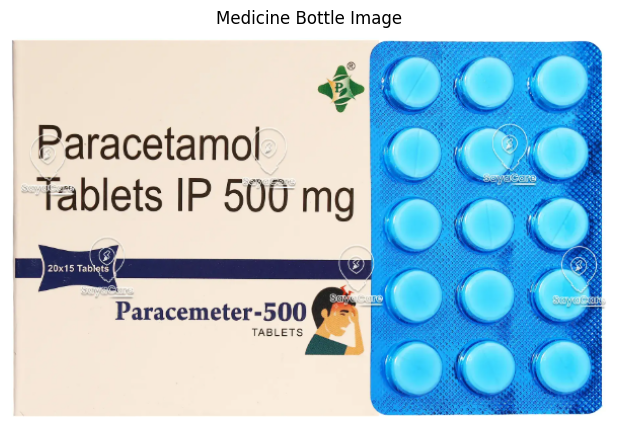

In [17]:
# Display original image
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Medicine Bottle Image")
plt.axis("off")
plt.show()

In [18]:

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Apply noise removal
gray = cv2.GaussianBlur(gray, (3, 3), 0)


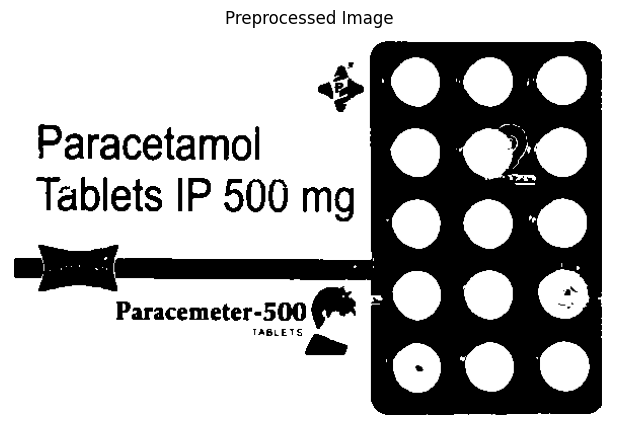

In [19]:

# Apply thresholding
processed = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)[1]

# Display processed image
plt.figure(figsize=(8, 5))
plt.imshow(processed, cmap='gray')
plt.title("Preprocessed Image")
plt.axis("off")
plt.show()


In [ ]:
# Extract text using OCR
extracted_text = pytesseract.image_to_string(processed)

print("\n========== MEDICINE LABEL INFORMATION ==========")
print("\nExtracted Text:\n")
print(extracted_text)

# Extract important information
lines = [line.strip() for line in extracted_text.split('\n') if line.strip()]

print("\n========== IMPORTANT DETAILS ==========")

In [ ]:
# Extract important information
lines = [line.strip() for line in extracted_text.split('\n') if line.strip()]

print("\n========== IMPORTANT DETAILS ==========")

# Medicine name (first non-empty line as a candidate)
if lines:
    print("Possible Medicine Name:", lines[0])


In [ ]:

# Extract dosage
dosage = re.findall(
    r'\b\d+(?:\.\d+)?\s*(?:mg|mcg|g|ml|µg)\b',
    extracted_text,
    re.IGNORECASE
)

print("Dosage:", ", ".join(dosage) if dosage else "Not detected")

In [ ]:
# Extract expiry date
expiry = re.findall(
    r'(?:EXP|EXPIRY|EXPIRES|EXP DATE)[:\s-]*'
    r'([0-9]{1,2}[/-][0-9]{2,4}|[0-9]{4})',
    extracted_text,
    re.IGNORECASE
)

print("Expiry Date:", ", ".join(expiry) if expiry else "Not detected")

In [ ]:
# Extract manufacturing date
mfg = re.findall(
    r'(?:MFG|MFD|MANUFACTURING DATE)[:\s-]*'
    r'([0-9]{1,2}[/-][0-9]{2,4}|[0-9]{4})',
    extracted_text,
    re.IGNORECASE
)

print("Manufacturing Date:", ", ".join(mfg) if mfg else "Not detected")


In [ ]:
# Extract batch number
batch = re.findall(
    r'(?:BATCH|BATCH NO|BATCH NUMBER|B\.NO)[:\s-]*([A-Z0-9-]+)',
    extracted_text,
    re.IGNORECASE
)

print("Batch Number:", ", ".join(batch) if batch else "Not detected")


In [ ]:
# Cognitive assistant response
print("\n========== COGNITIVE ASSISTANT ==========")

if expiry:
    print("Expiry information was detected. Please verify it against the original label.")
else:
    print("Expiry date could not be identified. Please check the label manually.")

print("\nPlease consult a pharmacist or healthcare professional")
print("before making any medication-related decisions.")